# Sales Forecasting & Business Intelligence Platform

## Time Series Analysis

### Objective

This phase investigates the temporal characteristics of daily
net revenue before feature engineering and model training.

The analysis focuses on:

- Time-series integrity
- Trend
- Weekly seasonality
- Monthly and yearly patterns
- Seasonal decomposition
- Stationarity
- Autocorrelation
- Partial autocorrelation
- Outliers and unusual observations
- Daily versus weekly forecasting granularity
- Forecast target definition
- Chronological train/validation/test design

### Forecasting Objective

Primary target:

`net_revenue`

Forecast horizons:

- 30 days
- 60 days
- 90 days


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import (
    seasonal_decompose,
)

from statsmodels.tsa.stattools import (
    adfuller,
    kpss,
    acf,
    pacf,
)

from statsmodels.graphics.tsaplots import (
    plot_acf,
    plot_pacf,
)

from ml.data.loader import (
    load_daily_revenue,
)


pd.set_option(
    "display.max_columns",
    None,
)

pd.set_option(
    "display.float_format",
    "{:,.2f}".format,
)

In [2]:
#Load Daily Revenue
daily = load_daily_revenue()

daily.head()

,date,gross_revenue,transaction_lines,invoices,return_revenue,return_lines,net_revenue,return_rate,year,month,day_of_week,is_weekend
0,2009-12-01,"54,351.23","3,068.00",119.00,"-1,340.47",110.00,"53,010.76",0.02,2009,12,1,0
1,2009-12-02,"63,172.58","3,208.00",115.00,-588.92,20.00,"62,583.66",0.01,2009,12,2,0
2,2009-12-03,"73,972.45","2,931.00",124.00,"-5,944.86",44.00,"68,027.59",0.08,2009,12,3,0
3,2009-12-04,"40,582.32","2,479.00",89.00,-386.52,27.00,"40,195.80",0.01,2009,12,4,0
4,2009-12-05,"9,803.05",400.00,30.00,0.00,0.00,"9,803.05",0.00,2009,12,5,1


In [3]:
print(
    "Shape:",
    daily.shape,
)

print(
    "Start:",
    daily["date"].min(),
)

print(
    "End:",
    daily["date"].max(),
)

Shape: (739, 12)
Start: 2009-12-01 00:00:00
End: 2011-12-09 00:00:00


In [4]:
# Sort time series
daily = (
    daily
    .sort_values("date")
    .reset_index(drop=True)
)
# checking no error
assert daily[
    "date"
].is_monotonic_increasing

In [5]:
TARGET = "net_revenue"
DATE_COLUMN = "date"
ts = (
    daily
    .set_index(DATE_COLUMN)
    [TARGET]
    .astype(float)
)

ts.head()

date
2009-12-01   53,010.76
2009-12-02   62,583.66
2009-12-03   68,027.59
2009-12-04   40,195.80
2009-12-05    9,803.05
Name: net_revenue, dtype: float64

## Forecast Target

The primary forecasting target is `net_revenue`.

Net revenue is selected instead of gross revenue because it reflects
the financial impact of both successful sales and returns/cancellations.

Therefore:

Net Revenue = Gross Revenue + Return Revenue

where return revenue is represented as a negative value.

Forecasting net revenue provides a more business-relevant estimate
of the revenue the company retains after transaction reversals.

In [6]:
# Time-Series Integrity
print(
    "Missing target:",
    ts.isna().sum(),
)

print(
    "Duplicate dates:",
    ts.index.duplicated().sum(),
)

Missing target: 0
Duplicate dates: 0


In [7]:
# check continuous daily frequency
expected_index = pd.date_range(
    start=ts.index.min(),
    end=ts.index.max(),
    freq="D",
)

missing_dates = (
    expected_index
    .difference(ts.index)
)

print(
    "Expected days:",
    len(expected_index),
)

print(
    "Actual days:",
    len(ts),
)

print(
    "Missing calendar days:",
    len(missing_dates),
)

Expected days: 739
Actual days: 739
Missing calendar days: 0


In [8]:
# Explicit Daily Frequency
ts = ts.asfreq("D")
print(
    "Frequency:",
    ts.index.freq,
)

Frequency: <Day>


In [9]:
# Basic Target Statistics
ts.describe()
print(
    f"Mean   : £{ts.mean():,.2f}"
)

print(
    f"Median : £{ts.median():,.2f}"
)

print(
    f"Std    : £{ts.std():,.2f}"
)

print(
    f"Min    : £{ts.min():,.2f}"
)

print(
    f"Max    : £{ts.max():,.2f}"
)

Mean   : £26,237.79
Median : £24,708.59
Std    : £20,454.77
Min    : £-1,727.65
Max    : £116,903.12


In [10]:
# Zero / Negative Revenue Days
zero_days = (
    ts == 0
).sum()

negative_days = (
    ts < 0
).sum()

positive_days = (
    ts > 0
).sum()

print(
    f"Positive days : {positive_days}"
)

print(
    f"Zero days     : {zero_days}"
)

print(
    f"Negative days : {negative_days}"
)

print(
    f"Zero-day rate: "
    f"{zero_days / len(ts):.2%}"
)

Positive days : 602
Zero days     : 135
Negative days : 2
Zero-day rate: 18.27%


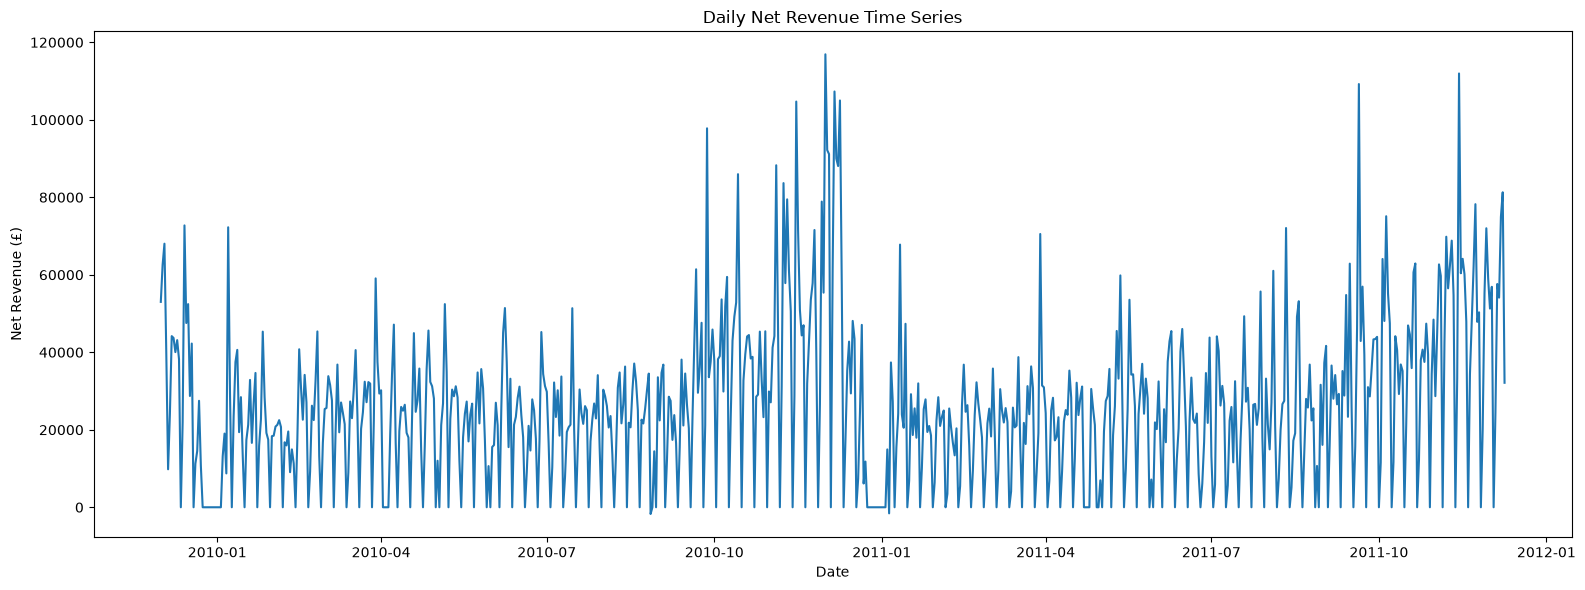

In [11]:
# Raw Time Series
plt.figure(
    figsize=(16, 6)
)

plt.plot(
    ts.index,
    ts.values,
)

plt.title(
    "Daily Net Revenue Time Series"
)

plt.xlabel("Date")
plt.ylabel("Net Revenue (£)")

plt.tight_layout()
plt.show()

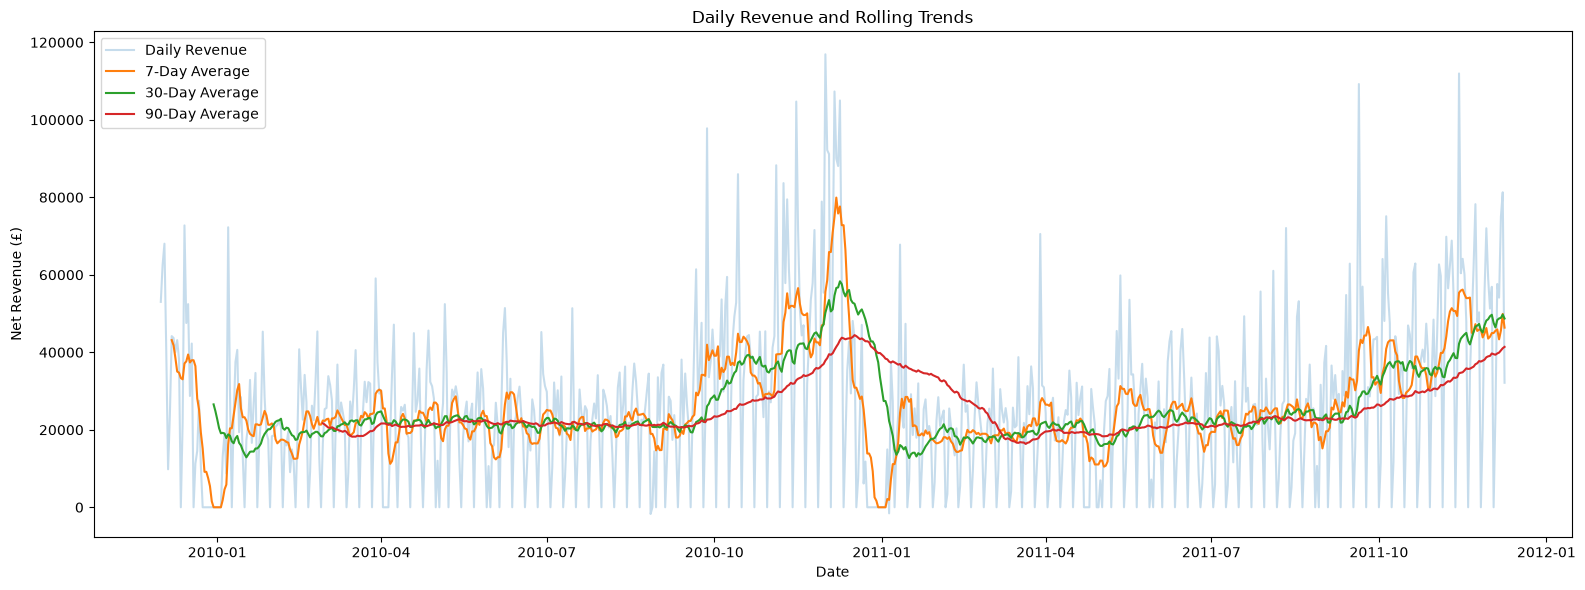

In [12]:
# Rolling Trend
rolling_7 = (
    ts
    .rolling(
        window=7,
    )
    .mean()
)

rolling_30 = (
    ts
    .rolling(
        window=30,
    )
    .mean()
)

rolling_90 = (
    ts
    .rolling(
        window=90,
    )
    .mean()
)

# Plot
plt.figure(
    figsize=(16, 6)
)

plt.plot(
    ts.index,
    ts,
    alpha=0.25,
    label="Daily Revenue",
)

plt.plot(
    rolling_7.index,
    rolling_7,
    label="7-Day Average",
)

plt.plot(
    rolling_30.index,
    rolling_30,
    label="30-Day Average",
)

plt.plot(
    rolling_90.index,
    rolling_90,
    label="90-Day Average",
)

plt.title(
    "Daily Revenue and Rolling Trends"
)

plt.xlabel("Date")
plt.ylabel("Net Revenue (£)")

plt.legend()

plt.tight_layout()
plt.show()

In [13]:
#Weekly Seasonality
seasonality_df = (
    ts
    .rename("net_revenue")
    .to_frame()
    .reset_index()
)

seasonality_df[
    "day_of_week"
] = (
    seasonality_df[
        "date"
    ].dt.dayofweek
)

seasonality_df[
    "day_name"
] = (
    seasonality_df[
        "date"
    ].dt.day_name()
)

# Order
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]
# Average
weekday_pattern = (
    seasonality_df
    .groupby(
        "day_name"
    )["net_revenue"]
    .agg(
        [
            "mean",
            "median",
            "std",
            "count",
        ]
    )
    .reindex(
        weekday_order
    )
)

weekday_pattern

,mean,median,std,count
day_name,,,,
Monday,"32,096.35","27,303.99","22,188.96",105
Tuesday,"35,559.34","31,079.44","17,255.87",106
Wednesday,"32,262.81","28,041.22","18,479.34",106
Thursday,"38,100.88","33,642.32","19,494.97",106
Friday,"28,037.37","25,986.21","15,963.13",106
Saturday,93.36,0.00,956.68,105
Sunday,"17,238.16","16,772.39","10,513.79",105


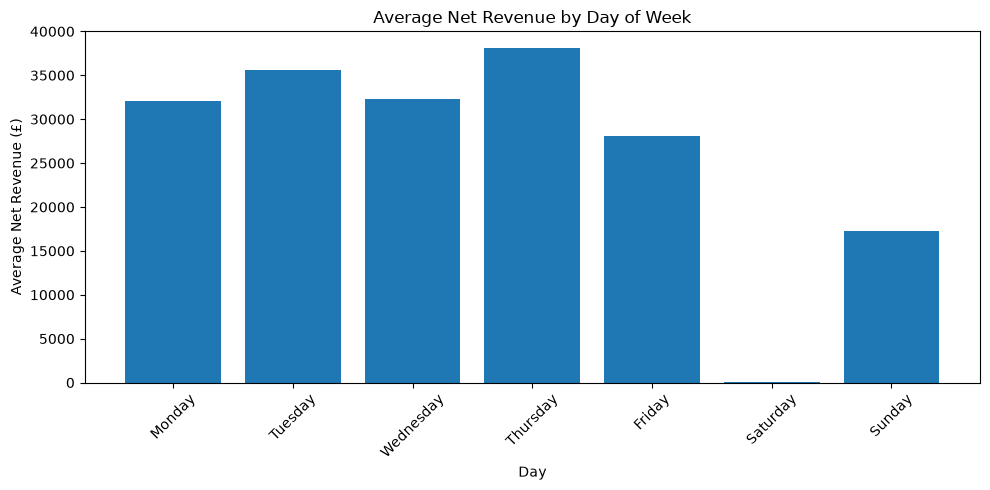

In [14]:
# Weekday pattern plot
plt.figure(
    figsize=(10, 5)
)

plt.bar(
    weekday_pattern.index,
    weekday_pattern["mean"],
)

plt.title(
    "Average Net Revenue by Day of Week"
)

plt.xlabel("Day")
plt.ylabel("Average Net Revenue (£)")

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

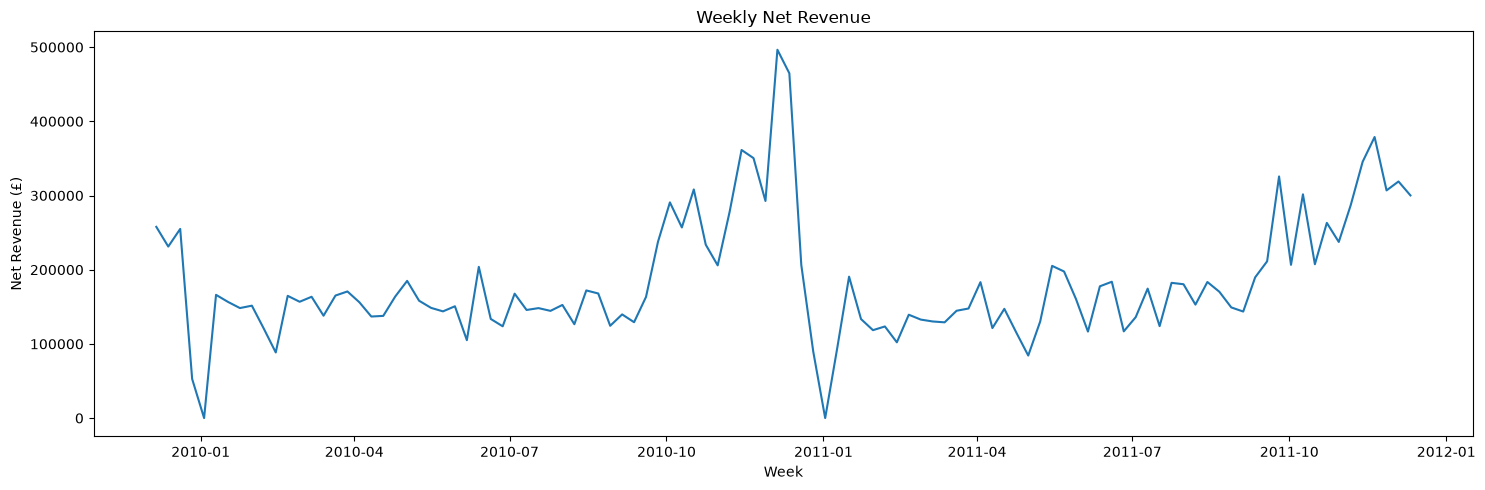

In [15]:
# Weekly Revenue Series
weekly_ts = (
    ts
    .resample("W-SUN")
    .sum()
)

weekly_ts.head()
# Plot
plt.figure(
    figsize=(15, 5)
)

plt.plot(
    weekly_ts.index,
    weekly_ts.values,
)

plt.title(
    "Weekly Net Revenue"
)

plt.xlabel("Week")
plt.ylabel("Net Revenue (£)")

plt.tight_layout()
plt.show()

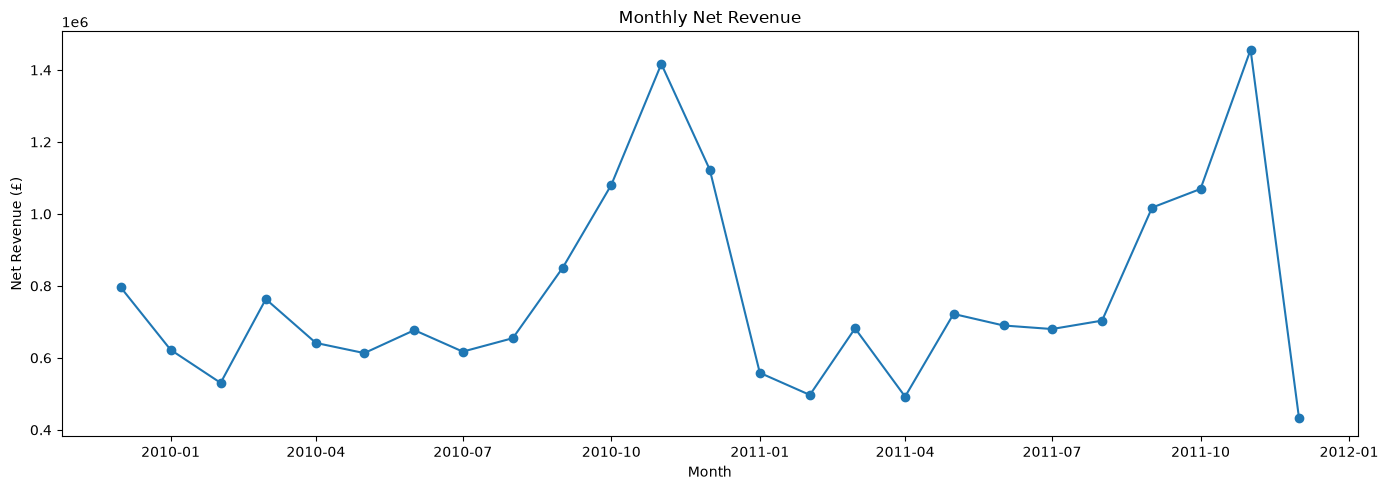

In [16]:
# Monthly Time Series
monthly_ts = (
    ts
    .resample("MS")
    .sum()
)
# Plot
plt.figure(
    figsize=(14, 5)
)

plt.plot(
    monthly_ts.index,
    monthly_ts.values,
    marker="o",
)

plt.title(
    "Monthly Net Revenue"
)

plt.xlabel("Month")
plt.ylabel("Net Revenue (£)")

plt.tight_layout()
plt.show()

In [17]:
# Seasonal Decomposition
weekly_decomposition = (
    seasonal_decompose(
        ts,
        model="additive",
        period=7,
        extrapolate_trend="freq",
    )
)

C:\Users\Tien\AppData\Local\Temp\ipykernel_27212\3102055911.py:3: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  seasonal_decompose(


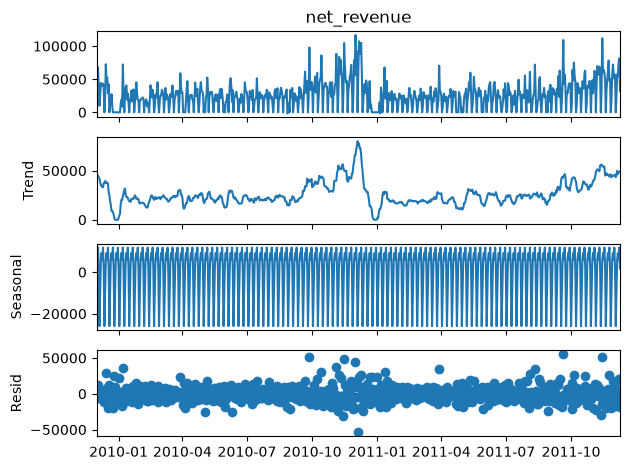

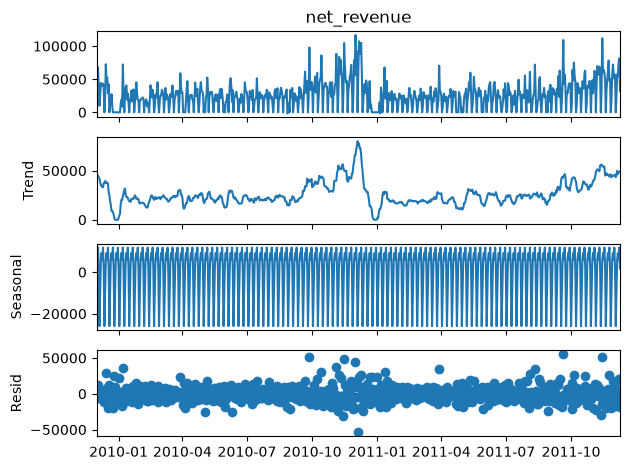

In [18]:
# Plot decomposition
weekly_decomposition.plot()

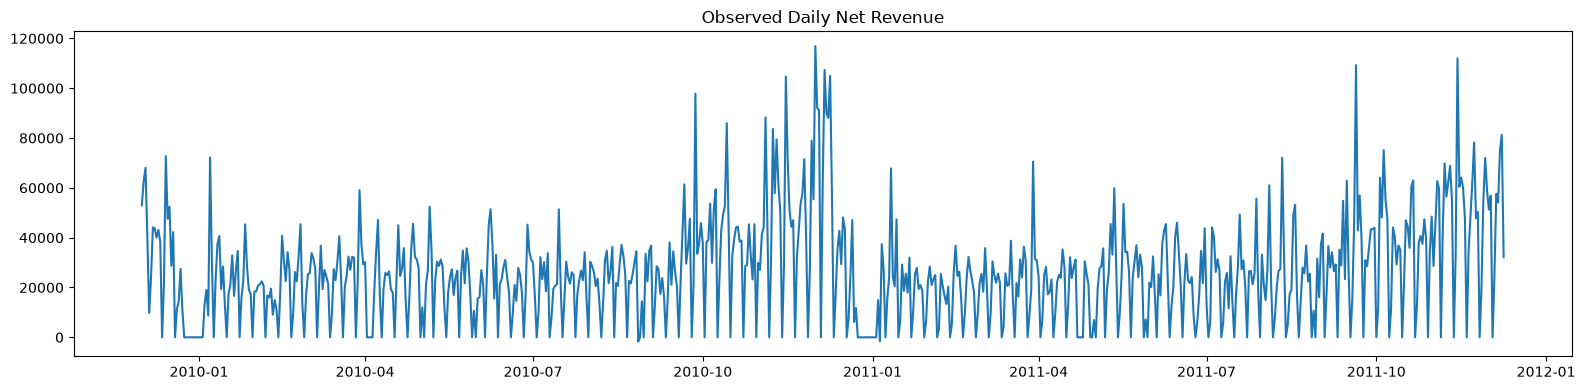

In [19]:
# split component
plt.figure(
    figsize=(16, 4)
)

plt.plot(
    weekly_decomposition.observed
)

plt.title(
    "Observed Daily Net Revenue"
)

plt.tight_layout()
plt.show()

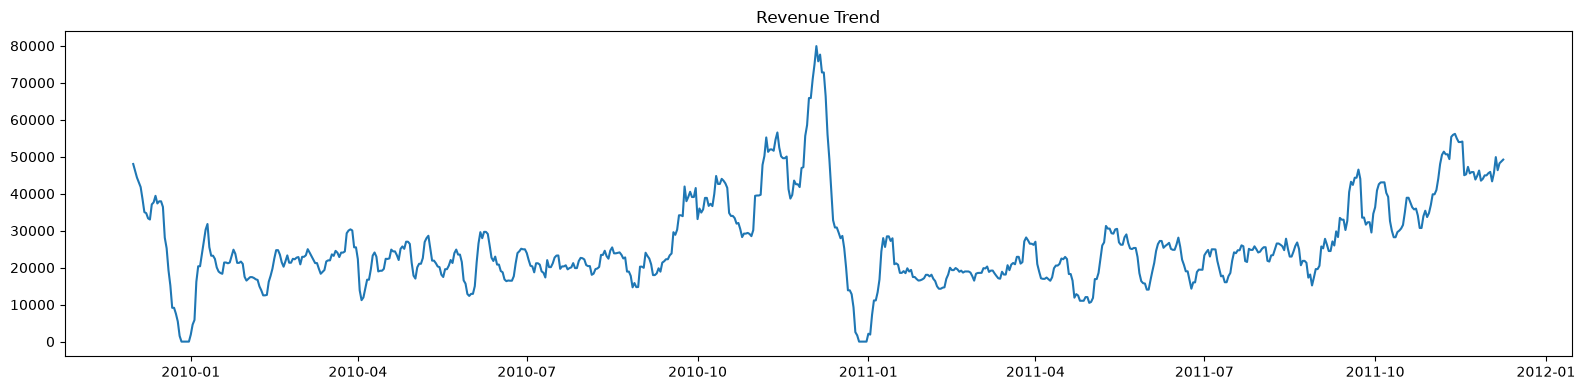

In [20]:
#Trend
plt.figure(
    figsize=(16, 4)
)

plt.plot(
    weekly_decomposition.trend
)

plt.title(
    "Revenue Trend"
)

plt.tight_layout()
plt.show()

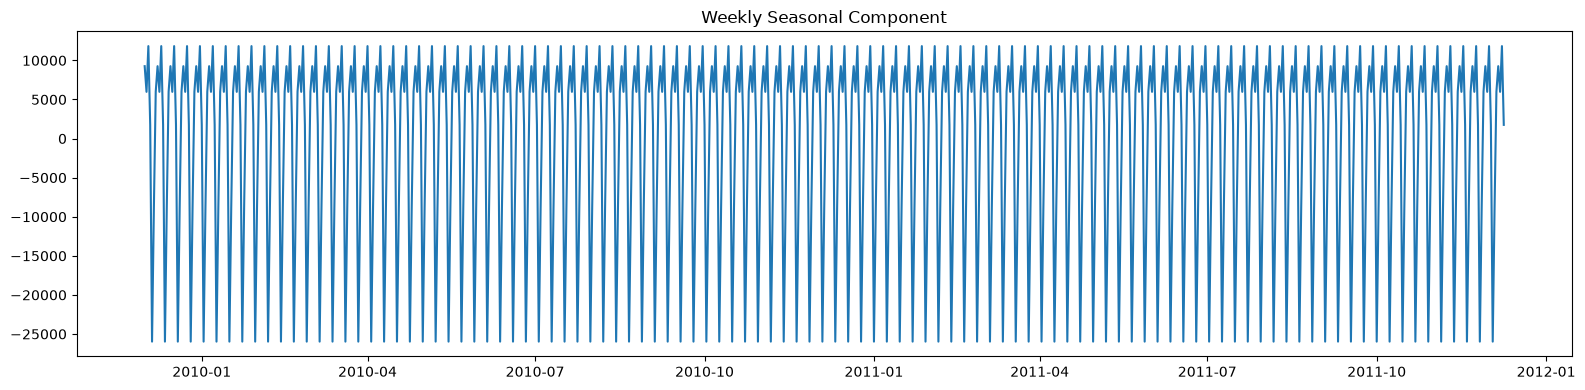

In [21]:
# Seasonality
plt.figure(
    figsize=(16, 4)
)

plt.plot(
    weekly_decomposition.seasonal
)

plt.title(
    "Weekly Seasonal Component"
)

plt.tight_layout()
plt.show()

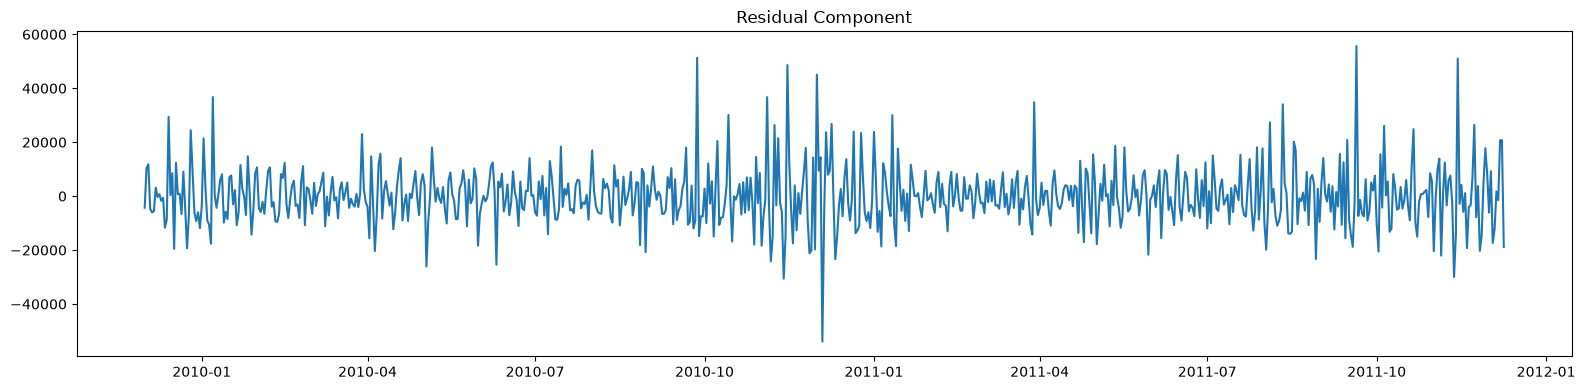

In [22]:
# Residual
plt.figure(
    figsize=(16, 4)
)

plt.plot(
    weekly_decomposition.resid
)

plt.title(
    "Residual Component"
)

plt.tight_layout()
plt.show()

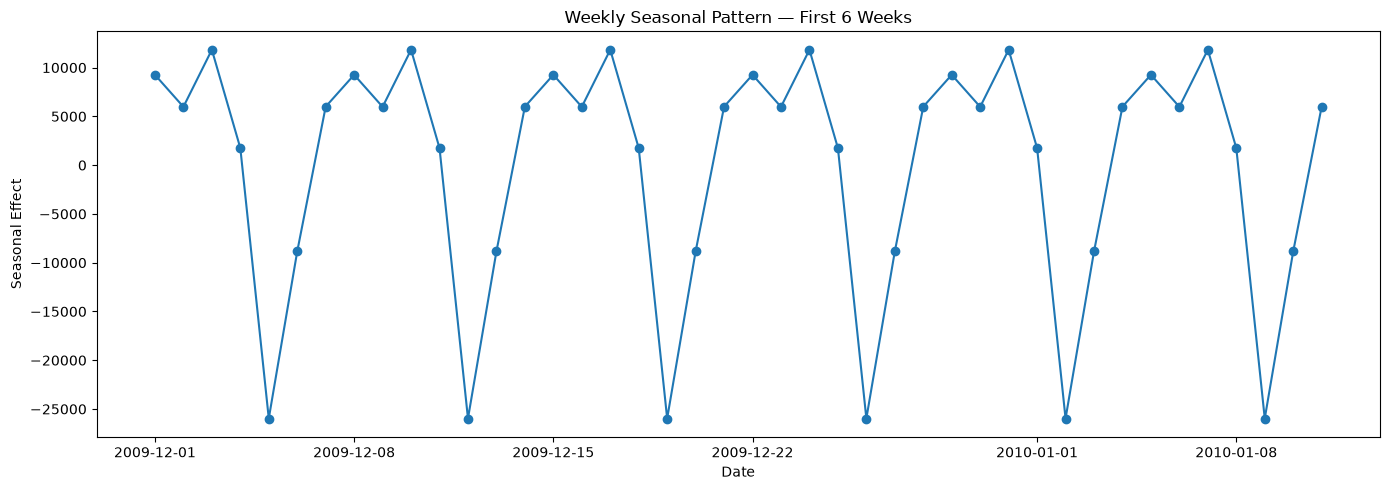

In [23]:
# Zoom Weekly Seasonal Component
sample_seasonal = (
    weekly_decomposition
    .seasonal
    .iloc[:42]
)
# Plot
plt.figure(
    figsize=(14, 5)
)

plt.plot(
    sample_seasonal.index,
    sample_seasonal.values,
    marker="o",
)

plt.title(
    "Weekly Seasonal Pattern — First 6 Weeks"
)

plt.xlabel("Date")
plt.ylabel("Seasonal Effect")

plt.tight_layout()
plt.show()

In [24]:
# Yearly Seasonality
yearly_decomposition = (
    seasonal_decompose(
        ts,
        model="additive",
        period=365,
        extrapolate_trend="freq",
    )
)

C:\Users\Tien\AppData\Local\Temp\ipykernel_27212\3398620718.py:3: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  seasonal_decompose(


### Yearly Seasonality Limitation

The dataset contains approximately two years of history.

Although a 365-day decomposition can be explored, there are too few
complete annual cycles to make strong conclusions about yearly
seasonality.

Therefore, yearly seasonality should be interpreted cautiously.

In [25]:
# Monthly seasonal pattern
monthly_pattern_df = (
    monthly_ts
    .rename("net_revenue")
    .to_frame()
    .reset_index()
)

monthly_pattern_df[
    "month"
] = (
    monthly_pattern_df[
        "date"
    ].dt.month
)
# Average
monthly_pattern = (
    monthly_pattern_df
    .groupby("month")
    ["net_revenue"]
    .mean()
)

monthly_pattern

month
1      590,464.03
2      513,772.32
3      722,630.61
4      566,944.45
5      667,682.41
6      683,525.55
7      648,761.24
8      679,142.48
9      934,351.32
10   1,074,989.85
11   1,436,421.50
12     784,119.33
Name: net_revenue, dtype: float64

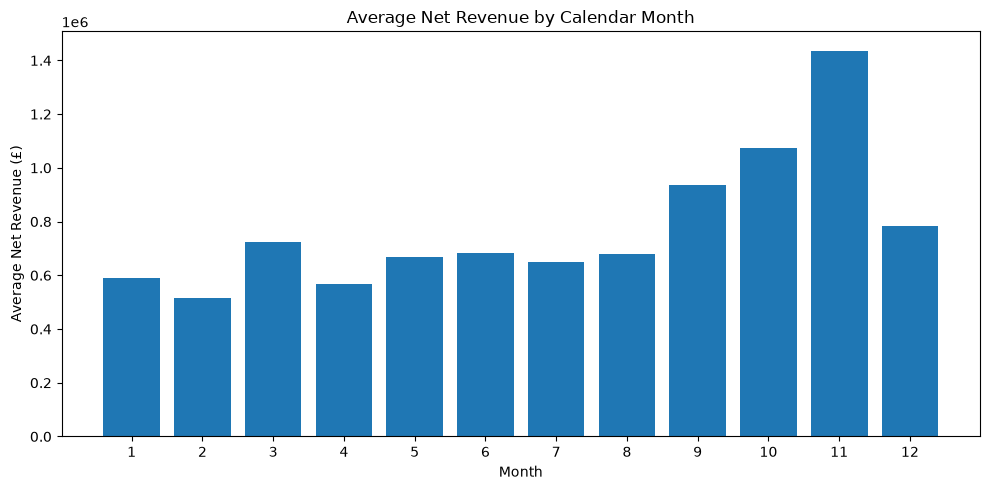

In [27]:
# Plot
plt.figure(
    figsize=(10, 5)
)

plt.bar(
    monthly_pattern.index,
    monthly_pattern.values,
)

plt.title(
    "Average Net Revenue by Calendar Month"
)

plt.xlabel("Month")
plt.ylabel("Average Net Revenue (£)")

plt.xticks(
    range(1, 13)
)

plt.tight_layout()
plt.show()

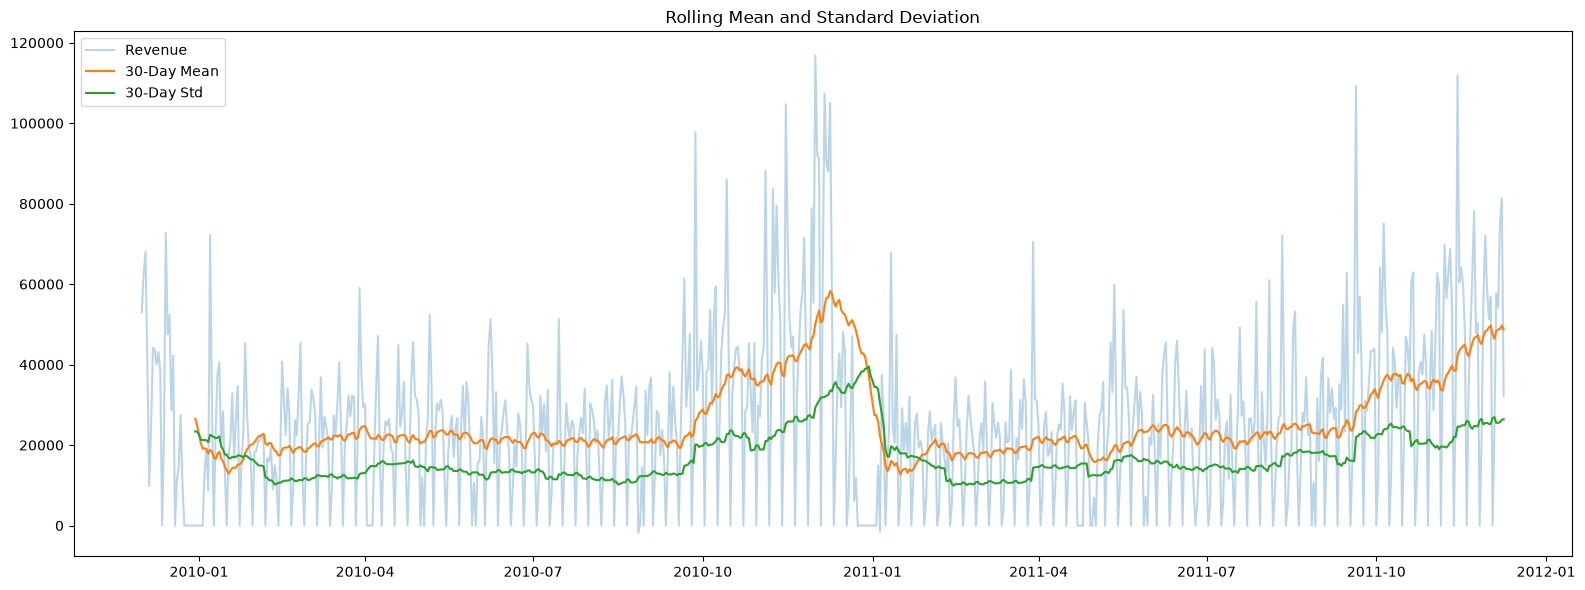

In [28]:
# Rolling Mean / Standard Deviation
rolling_mean_30 = (
    ts
    .rolling(30)
    .mean()
)

rolling_std_30 = (
    ts
    .rolling(30)
    .std()
)

# Plot
plt.figure(
    figsize=(16, 6)
)

plt.plot(
    ts.index,
    ts,
    alpha=0.3,
    label="Revenue",
)

plt.plot(
    rolling_mean_30.index,
    rolling_mean_30,
    label="30-Day Mean",
)

plt.plot(
    rolling_std_30.index,
    rolling_std_30,
    label="30-Day Std",
)

plt.title(
    "Rolling Mean and Standard Deviation"
)

plt.legend()

plt.tight_layout()
plt.show()

In [29]:
# ADF Test
def run_adf_test(
    series: pd.Series,
) -> dict:

    clean_series = (
        series
        .dropna()
        .astype(float)
    )

    result = adfuller(
        clean_series,
        autolag="AIC",
    )

    output = {
        "test_statistic": result[0],
        "p_value": result[1],
        "lags_used": result[2],
        "observations": result[3],
    }

    return output

adf_result = run_adf_test(
    ts
)

adf_result

C:\Users\Tien\AppData\Local\Temp\ipykernel_27212\3299631223.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(


{'test_statistic': -2.686004663073705,
 'p_value': 0.07649154203253783,
 'lags_used': 20,
 'observations': 718}

In [30]:
# Interpret
if adf_result["p_value"] < 0.05:
    print(
        "Reject H0 → "
        "evidence suggests stationarity."
    )
else:
    print(
        "Fail to reject H0 → "
        "evidence suggests non-stationarity."
    )

Fail to reject H0 → evidence suggests non-stationarity.


In [31]:
# KPSS Test
def run_kpss_test(
    series: pd.Series,
) -> dict:

    clean_series = (
        series
        .dropna()
        .astype(float)
    )

    statistic, p_value, lags, _ = (
        kpss(
            clean_series,
            regression="c",
            nlags="auto",
        )
    )

    return {
        "test_statistic": statistic,
        "p_value": p_value,
        "lags_used": lags,
    }
kpss_result = run_kpss_test(
    ts
)

kpss_result

C:\Users\Tien\AppData\Local\Temp\ipykernel_27212\1687658156.py:13: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss(


{'test_statistic': np.float64(0.6043208828131736),
 'p_value': np.float64(0.022243556107893303),
 'lags_used': 11}

In [32]:
# Interpret
if kpss_result["p_value"] < 0.05:
    print(
        "Reject H0 → "
        "evidence suggests non-stationarity."
    )
else:
    print(
        "Fail to reject H0 → "
        "evidence supports stationarity."
    )

Reject H0 → evidence suggests non-stationarity.


## Stationarity Decision Matrix

| ADF | KPSS | Interpretation |
|---|---|---|
| Stationary | Stationary | Series is likely stationary |
| Non-stationary | Non-stationary | Series is likely non-stationary |
| Stationary | Non-stationary | Possible trend/structural effects |
| Non-stationary | Stationary | Results are inconclusive |

Stationarity tests should be interpreted together with the trend,
seasonality and rolling-statistics analysis rather than in isolation.

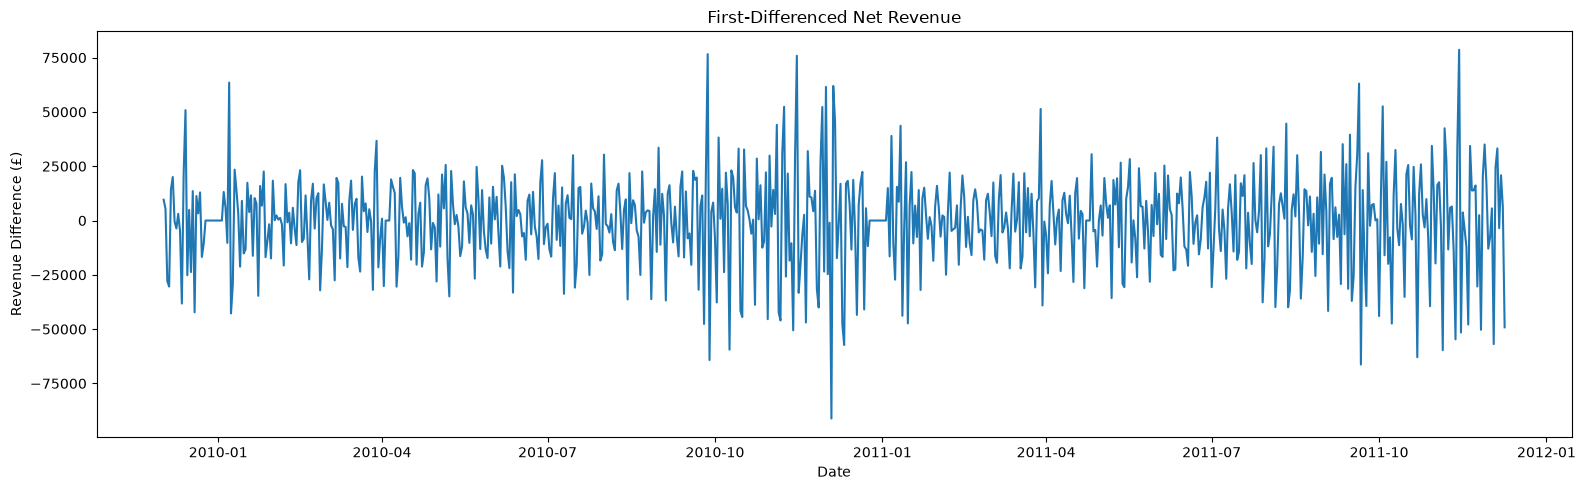

In [33]:
# First Difference
diff_1 = (
    ts
    .diff()
    .dropna()
)

# Plot
plt.figure(
    figsize=(16, 5)
)

plt.plot(
    diff_1.index,
    diff_1.values,
)

plt.title(
    "First-Differenced Net Revenue"
)

plt.xlabel("Date")
plt.ylabel("Revenue Difference (£)")

plt.tight_layout()
plt.show()

In [34]:
# ADF:
run_adf_test(
    diff_1
)

C:\Users\Tien\AppData\Local\Temp\ipykernel_27212\3299631223.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(


{'test_statistic': -8.346335529896185,
 'p_value': 3.078268824747073e-13,
 'lags_used': 20,
 'observations': 717}

In [35]:
# KPSS:
run_kpss_test(
    diff_1
)

C:\Users\Tien\AppData\Local\Temp\ipykernel_27212\1687658156.py:13: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss(


{'test_statistic': np.float64(0.40733155086840694),
 'p_value': np.float64(0.0739950211774108),
 'lags_used': 618}

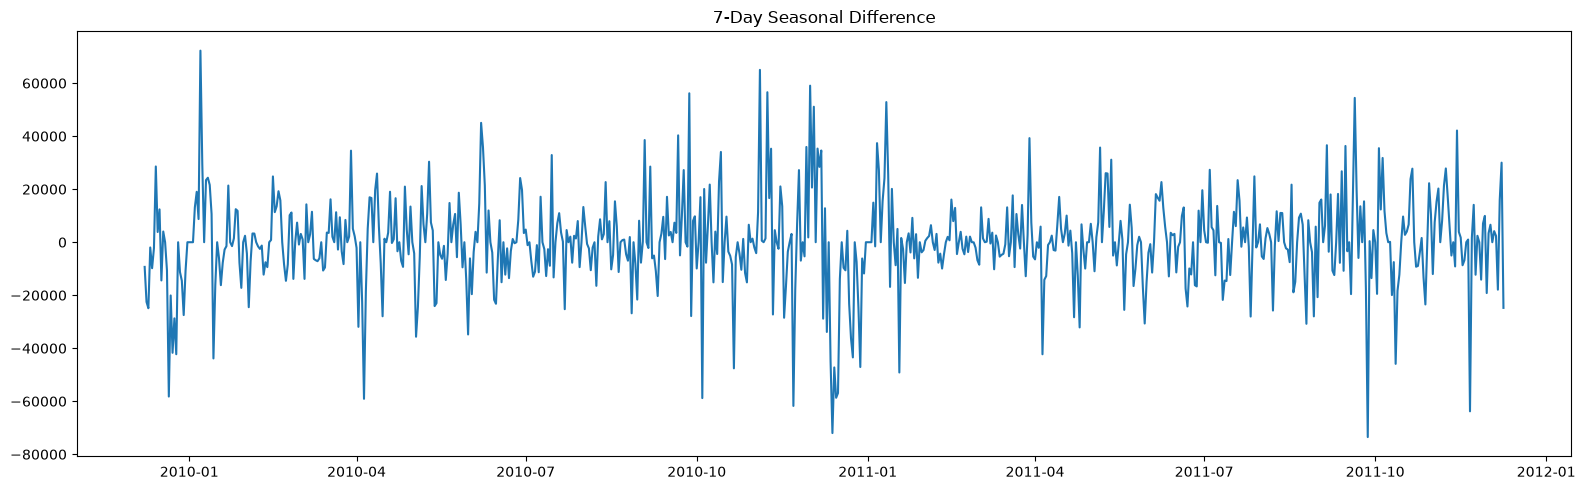

In [36]:
# Seasonal Difference
diff_7 = (
    ts
    .diff(7)
    .dropna()
)
# Plot
plt.figure(
    figsize=(16, 5)
)

plt.plot(
    diff_7.index,
    diff_7.values,
)

plt.title(
    "7-Day Seasonal Difference"
)

plt.tight_layout()
plt.show()

In [37]:
# Test
run_adf_test(
    diff_7
)

C:\Users\Tien\AppData\Local\Temp\ipykernel_27212\3299631223.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(


{'test_statistic': -8.532349407882222,
 'p_value': 1.0295571266174435e-13,
 'lags_used': 20,
 'observations': 711}

<Figure size 1400x500 with 0 Axes>

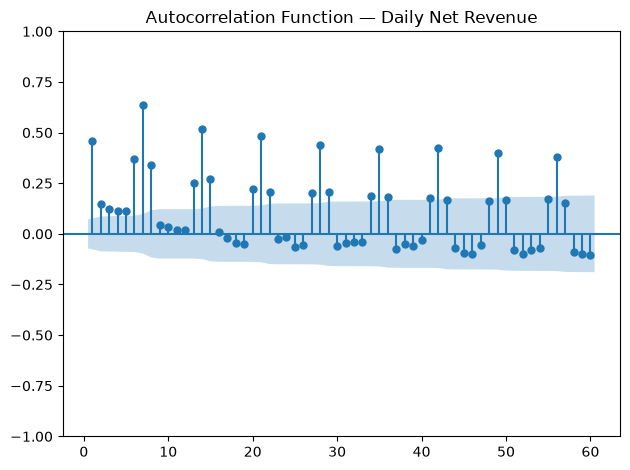

In [38]:
# Autocorrelation
# ACF
plt.figure(
    figsize=(14, 5)
)

plot_acf(
    ts,
    lags=60,
    zero=False,
)

plt.title(
    "Autocorrelation Function — Daily Net Revenue"
)

plt.tight_layout()
plt.show()

<Figure size 1400x500 with 0 Axes>

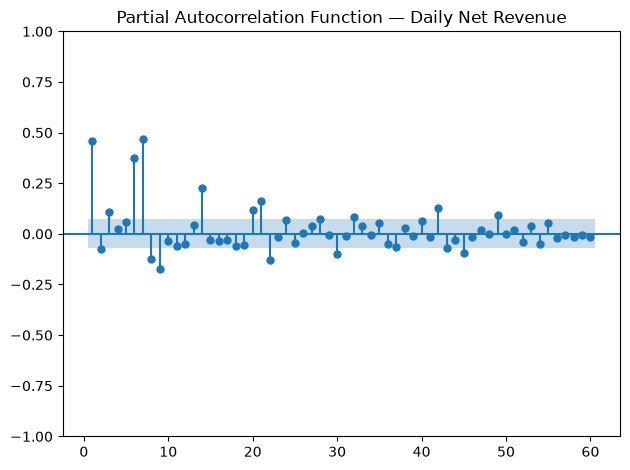

In [40]:
# PACF
plt.figure(
    figsize=(14, 5)
)

plot_pacf(
    ts,
    lags=60,
    method="ywm",
    zero=False,
)

plt.title(
    "Partial Autocorrelation Function — Daily Net Revenue"
)

plt.tight_layout()
plt.show()

In [41]:
# Numeric Autocorrelation
acf_values = acf(
    ts,
    nlags=60,
    fft=True,
)
acf_df = pd.DataFrame({
    "lag": range(
        len(acf_values)
    ),
    "acf": acf_values,
})
acf_df.head(31)

,lag,acf
0,0,1.00
1,1,0.46
2,2,0.15
3,3,0.12
4,4,0.11
5,5,0.11
6,6,0.37
7,7,0.64
8,8,0.34
9,9,0.04


In [42]:
# Candidate Lag Analysis
candidate_lags = [
    1,
    2,
    3,
    7,
    14,
    21,
    28,
    30,
    60,
]
lag_correlations = (
    acf_df[
        acf_df[
            "lag"
        ].isin(
            candidate_lags
        )
    ]
)

lag_correlations

,lag,acf
1,1,0.46
2,2,0.15
3,3,0.12
7,7,0.64
14,14,0.52
21,21,0.48
28,28,0.44
30,30,-0.06
60,60,-0.11


In [43]:
# Sort absolute
lag_correlations = (
    lag_correlations
    .assign(
        abs_acf=lambda x:
        x["acf"].abs()
    )
    .sort_values(
        "abs_acf",
        ascending=False,
    )
)

lag_correlations

,lag,acf,abs_acf
7,7,0.64,0.64
14,14,0.52,0.52
21,21,0.48,0.48
1,1,0.46,0.46
28,28,0.44,0.44
2,2,0.15,0.15
3,3,0.12,0.12
60,60,-0.11,0.11
30,30,-0.06,0.06


In [44]:
# IQR Detection
q1 = ts.quantile(0.25)
q3 = ts.quantile(0.75)

iqr = q3 - q1

lower_bound = (
    q1
    - 1.5 * iqr
)

upper_bound = (
    q3
    + 1.5 * iqr
)

# Detect
outlier_mask = (
    (ts < lower_bound)
    |
    (ts > upper_bound)
)

outliers = (
    ts[
        outlier_mask
    ]
    .sort_values(
        ascending=False
    )
)

print(
    "Potential IQR outliers:",
    len(outliers),
)

print(
    "Outlier rate:",
    f"{len(outliers) / len(ts):.2%}",
)

Potential IQR outliers: 28
Outlier rate: 3.79%


In [45]:
# Top Revenue Outliers
outliers.head(20)

date
2010-12-01   116,903.12
2011-11-14   111,958.62
2011-09-20   109,228.08
2010-12-06   107,307.74
2010-12-09   104,988.28
2010-11-15   104,708.97
2010-09-27    97,804.70
2010-12-02    92,176.64
2010-12-03    91,150.76
2010-12-07    89,989.40
2010-11-04    88,267.65
2010-12-08    88,070.44
2010-10-14    85,969.18
2010-11-08    83,662.44
2011-12-08    81,294.33
2010-11-10    79,469.50
2010-11-29    78,889.67
2011-11-23    78,223.52
2011-10-05    75,111.57
2011-12-07    74,952.61
Name: net_revenue, dtype: float64

In [46]:
# Low
outliers.tail(20)

date
2010-12-03   91,150.76
2010-12-07   89,989.40
2010-11-04   88,267.65
2010-12-08   88,070.44
2010-10-14   85,969.18
2010-11-08   83,662.44
2011-12-08   81,294.33
2010-11-10   79,469.50
2010-11-29   78,889.67
2011-11-23   78,223.52
2011-10-05   75,111.57
2011-12-07   74,952.61
2009-12-14   72,744.97
2010-01-07   72,262.07
2011-08-11   72,071.89
2011-11-29   72,008.09
2010-11-25   71,559.84
2010-11-16   71,402.02
2011-03-29   70,531.47
2011-11-07   69,824.57
Name: net_revenue, dtype: float64

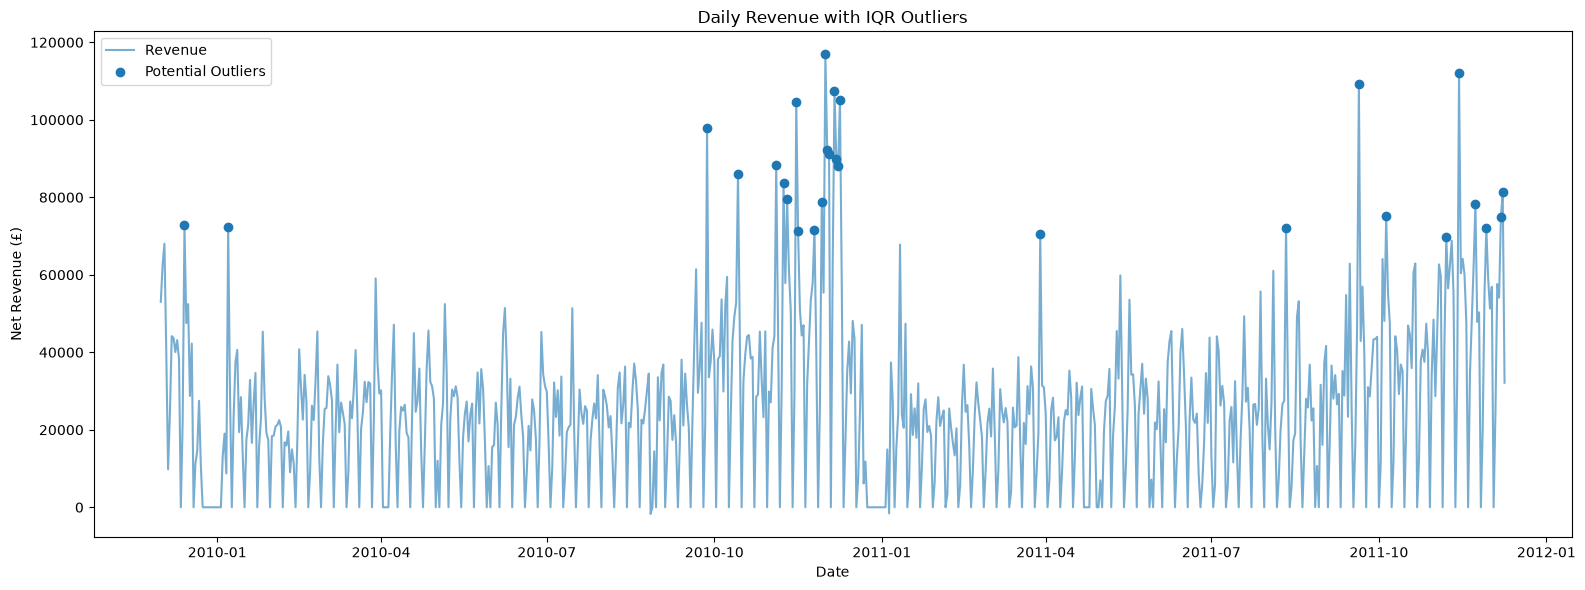

In [47]:
# Outlier Plot
plt.figure(
    figsize=(16, 6)
)

plt.plot(
    ts.index,
    ts.values,
    alpha=0.6,
    label="Revenue",
)

plt.scatter(
    ts[
        outlier_mask
    ].index,

    ts[
        outlier_mask
    ].values,

    label="Potential Outliers",
)

plt.title(
    "Daily Revenue with IQR Outliers"
)

plt.xlabel("Date")
plt.ylabel("Net Revenue (£)")

plt.legend()

plt.tight_layout()
plt.show()

In [50]:
# Inspect original transactions
top_outlier_dates = (
    outliers
    .head(10)
    .index
)

top_outlier_dates

DatetimeIndex(['2010-12-01', '2011-11-14', '2011-09-20', '2010-12-06',
               '2010-12-09', '2010-11-15', '2010-09-27', '2010-12-02',
               '2010-12-03', '2010-12-07'],
              dtype='datetime64[us]', name='date', freq=None)

In [49]:
from ml.data.loader import (
    load_valid_sales,
)

sales = load_valid_sales()

D:\Research_Project\sales-forecasting-platform\src\sales_forecasting\data\loader.py:104: DtypeWarning: Columns (0: invoice_no) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(


In [51]:
# create date
sales[
    "invoice_day"
] = (
    sales[
        "invoice_date"
    ].dt.normalize()
)
# Inspect
outlier_transactions = (
    sales[
        sales[
            "invoice_day"
        ].isin(
            top_outlier_dates
        )
    ]
)

outlier_transactions[
    [
        "invoice_day",
        "invoice_no",
        "stock_code",
        "description",
        "quantity",
        "unit_price",
        "line_revenue",
    ]
].sort_values(
    "line_revenue",
    ascending=False,
).head(30)

,invoice_day,invoice_no,stock_code,description,quantity,unit_price,line_revenue
519186,2010-12-07,537632,AMAZONFEE,AMAZON FEE,1,"13,541.33","13,541.33"
497490,2010-12-07,537632,AMAZONFEE,AMAZON FEE,1,"13,541.33","13,541.33"
344133,2010-09-27,524159,M,Manual,1,"10,468.80","10,468.80"
842246,2011-09-20,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,"7,144.72"
443147,2010-11-15,533027,22086,PAPER CHAIN KIT 50'S CHRISTMAS,835,6.95,"5,803.25"
957733,2011-11-14,576365,22086,PAPER CHAIN KIT 50'S CHRISTMAS,688,6.95,"4,781.60"
344305,2010-09-27,524181,21622,VINTAGE UNION JACK CUSHION COVER,648,6.89,"4,464.72"
344307,2010-09-27,524181,21624,VINTAGE UNION JACK DOORSTOP,648,5.96,"3,862.08"
520588,2010-12-07,537659,21623,VINTAGE UNION JACK MEMOBOARD,600,6.38,"3,828.00"
498892,2010-12-07,537659,21623,VINTAGE UNION JACK MEMOBOARD,600,6.38,"3,828.00"


In [52]:
# Daily vs Weekly Granularity
granularity_summary = pd.DataFrame({
    "Metric": [
        "Observations",
        "Mean",
        "Std",
        "Coefficient of Variation",
        "Zero Rate",
    ],

    "Daily": [
        len(ts),
        ts.mean(),
        ts.std(),
        ts.std() / ts.mean(),
        (ts == 0).mean(),
    ],

    "Weekly": [
        len(weekly_ts),
        weekly_ts.mean(),
        weekly_ts.std(),
        weekly_ts.std()
        / weekly_ts.mean(),
        (weekly_ts == 0).mean(),
    ],
})

granularity_summary

,Metric,Daily,Weekly
0,Observations,739.00,106.00
1,Mean,"26,237.79","182,921.98"
2,Std,"20,454.77","82,305.68"
3,Coefficient of Variation,0.78,0.45
4,Zero Rate,0.18,0.02


<!-- Compare Daily vs Weekly -->
## Daily
Advantages
+ Forecast exactly 30/60/90 days
+ Captures weekday patterns
+ More observations for ML
+ Suitable for dashboard daily forecast

Disadvantages
- Noisier
- More zero days
- More outliers
## Weekly
Advantages
+ Less noisy
+ Easier trend detection
+ Stable aggregate

Disadvantages
- Loses weekday pattern
- 30-day forecast becomes ~4.3 weeks
- Fewer training observations

In [53]:
# Forecast Horizons
FORECAST_HORIZONS = {
    "30_days": 30,
    "60_days": 60,
    "90_days": 90,
}

FORECAST_HORIZONS

{'30_days': 30, '60_days': 60, '90_days': 90}

# Business interpretation
30-day
→ operational planning

60-day
→ short-term planning

90-day
→ quarterly planning

# Train / Validation / Test Split
Past                                      Future
│                                             │
├──────────── TRAIN ────────────┤
                               ├─ VALIDATION ─┤
                                              ├── TEST ──┤

TEST       = last 90 days
VALIDATION = previous 90 days
TRAIN      = everything before

In [54]:
# Calculate split dates
TEST_DAYS = 90
VALIDATION_DAYS = 90

series_end = ts.index.max()

test_start = (
    series_end
    - pd.Timedelta(
        days=TEST_DAYS - 1
    )
)

validation_end = (
    test_start
    - pd.Timedelta(days=1)
)

validation_start = (
    validation_end
    - pd.Timedelta(
        days=VALIDATION_DAYS - 1
    )
)

print(
    "Series start:",
    ts.index.min().date(),
)

print(
    "Validation start:",
    validation_start.date(),
)

print(
    "Validation end:",
    validation_end.date(),
)

print(
    "Test start:",
    test_start.date(),
)

print(
    "Series end:",
    series_end.date(),
)

Series start: 2009-12-01
Validation start: 2011-06-13
Validation end: 2011-09-10
Test start: 2011-09-11
Series end: 2011-12-09


In [55]:
# Create splits
train_ts = (
    ts[
        ts.index
        < validation_start
    ]
)

validation_ts = (
    ts[
        (
            ts.index
            >= validation_start
        )
        &
        (
            ts.index
            <= validation_end
        )
    ]
)

test_ts = (
    ts[
        ts.index
        >= test_start
    ]
)
# check
print(
    "Train:",
    len(train_ts),
)

print(
    "Validation:",
    len(validation_ts),
)

print(
    "Test:",
    len(test_ts),
)

Train: 559
Validation: 90
Test: 90


In [56]:
# Validate no overlap
assert (
    train_ts.index.max()
    <
    validation_ts.index.min()
)

assert (
    validation_ts.index.max()
    <
    test_ts.index.min()
)

In [57]:
assert (
    len(
        train_ts.index
        .intersection(
            validation_ts.index
        )
    )
    == 0
)

assert (
    len(
        validation_ts.index
        .intersection(
            test_ts.index
        )
    )
    == 0
)

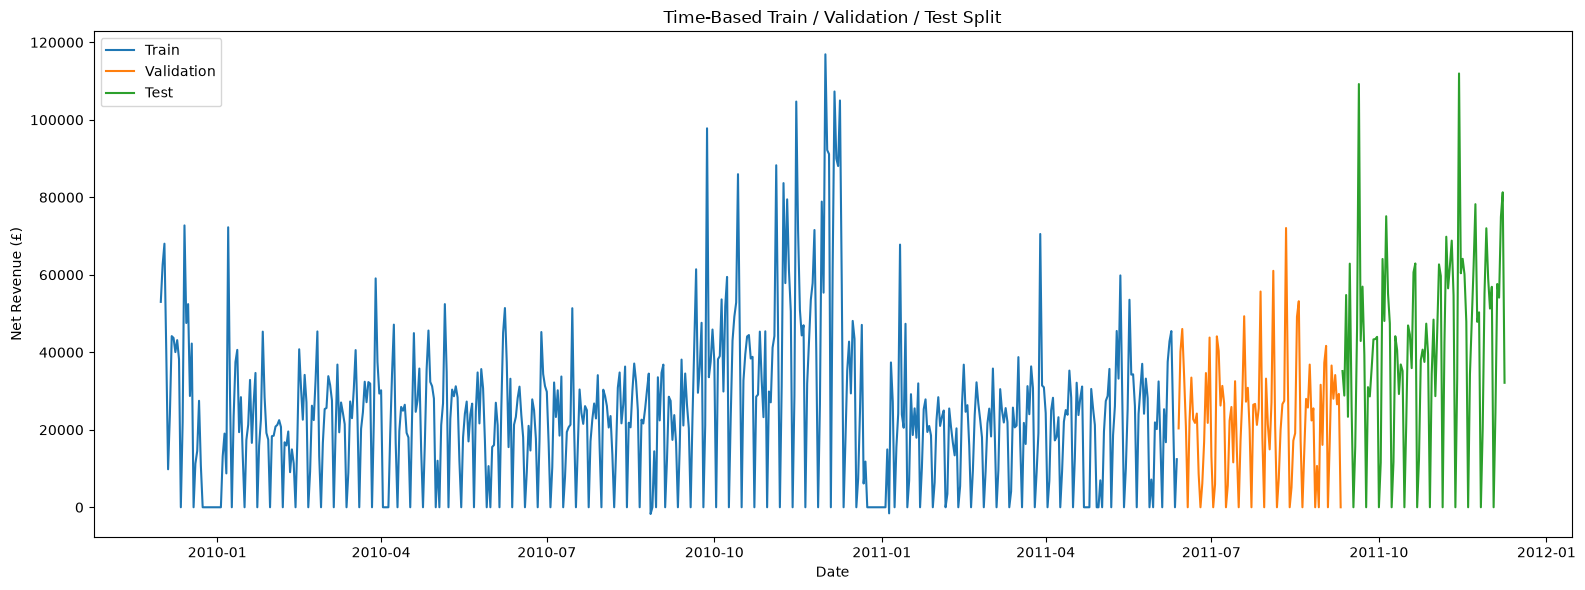

In [58]:
# Visualize Split
plt.figure(
    figsize=(16, 6)
)

plt.plot(
    train_ts.index,
    train_ts.values,
    label="Train",
)

plt.plot(
    validation_ts.index,
    validation_ts.values,
    label="Validation",
)

plt.plot(
    test_ts.index,
    test_ts.values,
    label="Test",
)

plt.title(
    "Time-Based Train / Validation / Test Split"
)

plt.xlabel("Date")
plt.ylabel("Net Revenue (£)")

plt.legend()

plt.tight_layout()
plt.show()

In [59]:
# Save Split Metadata
split_summary = pd.DataFrame({
    "split": [
        "train",
        "validation",
        "test",
    ],

    "start_date": [
        train_ts.index.min(),
        validation_ts.index.min(),
        test_ts.index.min(),
    ],

    "end_date": [
        train_ts.index.max(),
        validation_ts.index.max(),
        test_ts.index.max(),
    ],

    "observations": [
        len(train_ts),
        len(validation_ts),
        len(test_ts),
    ],
})

split_summary

,split,start_date,end_date,observations
0,train,2009-12-01,2011-06-12,559
1,validation,2011-06-13,2011-09-10,90
2,test,2011-09-11,2011-12-09,90


In [60]:
# Save Time-Series Analysis artifacts
from ml.config import (
    TIME_SERIES_DIR,
)

TIME_SERIES_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

split_summary.to_csv(
    TIME_SERIES_DIR
    / "split_summary.csv",
    index=False,
)

lag_correlations.to_csv(
    TIME_SERIES_DIR
    / "acf_candidate_lags.csv",
    index=False,
)

weekday_pattern.to_csv(
    TIME_SERIES_DIR
    / "weekday_pattern.csv",
)

monthly_pattern.to_csv(
    TIME_SERIES_DIR
    / "monthly_pattern.csv",
)

In [62]:
# Automated Analysis Summary
strongest_lag = (
    lag_correlations
    .iloc[0]
)

print("=" * 70)

print(
    "TIME SERIES ANALYSIS SUMMARY"
)

print("=" * 70)

print(
    f"Target              : "
    f"{TARGET}"
)

print(
    f"Granularity         : "
    f"Daily"
)

print(
    f"Observations        : "
    f"{len(ts):,}"
)

print(
    f"Date range          : "
    f"{ts.index.min().date()} "
    f"→ "
    f"{ts.index.max().date()}"
)

print(
    f"Zero revenue days   : "
    f"{zero_days:,}"
)

print(
    f"Negative days       : "
    f"{negative_days:,}"
)

print(
    f"Potential outliers  : "
    f"{len(outliers):,}"
)

print(
    f"Strong candidate lag: "
    f"{int(strongest_lag['lag'])}"
)

print(
    f"ACF                 : "
    f"{strongest_lag['acf']:.3f}"
)

print()

print(
    f"Train observations  : "
    f"{len(train_ts):,}"
)

print(
    f"Validation          : "
    f"{len(validation_ts):,}"
)

print(
    f"Test                : "
    f"{len(test_ts):,}"
)

TIME SERIES ANALYSIS SUMMARY
Target              : net_revenue
Granularity         : Daily
Observations        : 739
Date range          : 2009-12-01 → 2011-12-09
Zero revenue days   : 135
Negative days       : 2
Potential outliers  : 28
Strong candidate lag: 7
ACF                 : 0.638

Train observations  : 559
Validation          : 90
Test                : 90


# Final Markdown Conclusion

The time-series analysis established the temporal characteristics
of daily net revenue and defined the forecasting strategy.

### Forecast Target

The primary target is:

`net_revenue`

This metric incorporates both positive sales revenue and the
financial impact of returns and cancellations.

### Forecasting Granularity

Daily forecasting was selected as the primary granularity because:

- The required horizons are 30, 60 and 90 days.
- Daily observations preserve weekday effects.
- Weekly seasonal behavior can be represented directly.
- The daily dataset provides more training observations than
  weekly aggregation.

Weekly revenue remains useful as a secondary analytical series.

### Seasonality

The analysis investigates:

- Weekly patterns
- Calendar-month effects
- Potential annual seasonality

Annual seasonality should be interpreted cautiously because the
dataset contains only approximately two years of history.

### Autocorrelation

ACF and PACF analysis identified candidate lag relationships that
will guide feature engineering.

Potential candidate features include:

- lag_1
- lag_7
- lag_14
- lag_21
- lag_28
- lag_30

The final lag set will be selected based on observed autocorrelation
and validation performance rather than assumed in advance.

### Outliers

Potential revenue outliers were identified but not automatically
removed.

Extreme observations may represent genuine business events such as
bulk orders, seasonal peaks or unusual return activity and therefore
require investigation before treatment.

### Validation Strategy

A chronological split was selected:

- Training: historical observations before the validation period
- Validation: 90 days
- Test: final 90 days

No random shuffling is used.

This prevents future information from leaking into historical
training observations.

